Monthly aggregation

In [42]:
import sys
from pathlib import Path
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from matplotlib.colors import LinearSegmentedColormap

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data_loading import load_all_stations
from src.cleaning import replace_missing_values, convert_units

FIGURES_DIR = PROJECT_ROOT / 'figures'
FIGURES_DIR.mkdir(exist_ok=True)

raw = load_all_stations()
no_sentinels = replace_missing_values(raw)
cleaned = convert_units(no_sentinels)
print('Raw shape:', cleaned.shape)
print(cleaned[['STATION','DATE','TEMP','PRCP']].dtypes)
print(cleaned[['TEMP','PRCP']].head(3))
print('Nan Values in PRCP: ',cleaned['PRCP'].isna().sum())


Raw shape: (61130, 28)
STATION               str
DATE       datetime64[us]
TEMP              float64
PRCP              float64
dtype: object
        TEMP  PRCP
0  20.444444   0.0
1  21.333333   0.0
2  21.111111   0.0
Nan Values in PRCP:  825


Step 1: turning Daily weather Observations into Monthly observations


In [43]:
cleaned['MONTH'] = cleaned['DATE'].dt.to_period('M')
data = cleaned.groupby(['STATION','MONTH'])
monthly = data.agg(
    PRCP_VALID_DAYS = ('PRCP','count'),
    PRCP_TOTAL = ('PRCP', lambda x: x.sum(min_count=1))
).reset_index()

display(monthly.head())
print(monthly.shape[0]) 
print(monthly['PRCP_TOTAL'].isna().sum())



,STATION,MONTH,PRCP_VALID_DAYS,PRCP_TOTAL
0,41184099999,1996-01,29,0.0
1,41184099999,1996-02,27,0.0
2,41184099999,1996-03,28,0.0
3,41184099999,1996-04,30,0.0
4,41184099999,1996-05,31,0.0


2015
0


In [44]:
# Reconstruct full monthly calendar

all_months = pd.period_range('1996-01', '2023-12', freq='M')
stations = cleaned['STATION'].unique()

## generating all station-month combinations
full_index = pd.MultiIndex.from_product(
    [stations, all_months], names=['STATION', 'MONTH']

)

complete_monthly = (
    monthly
    .set_index(['STATION','MONTH'])
    .reindex(full_index)
    .reset_index()
)

print('Shape:', complete_monthly.shape)

rak_jan_2006 = complete_monthly[
    (complete_monthly['STATION'] == '41184099999') &
    (complete_monthly['MONTH'] == pd.Period('2006-01', freq='M'))
]

display(rak_jan_2006)

Shape: (2016, 4)


,STATION,MONTH,PRCP_VALID_DAYS,PRCP_TOTAL
120,41184099999,2006-01,NaN,NaN


In [45]:
monthly_base = complete_monthly.copy()
monthly_base['DAYS_IN_MONTH'] = monthly_base['MONTH'].dt.days_in_month
monthly_base['PRCP_COMPLETENESS'] = monthly_base['PRCP_VALID_DAYS'] / monthly_base['DAYS_IN_MONTH'] * 100

monthly_qc_28 = monthly_base.copy()
invalid_28 = ~(monthly_qc_28['PRCP_VALID_DAYS'] >= 28)
monthly_qc_28.loc[invalid_28, 'PRCP_TOTAL'] = np.nan

print("Total months:", len(monthly_qc_28))
print("Rejected months:", invalid_28.sum())
print("Valid PRCP totals:", monthly_qc_28['PRCP_TOTAL'].notna().sum())

Total months: 2016
Rejected months: 127
Valid PRCP totals: 1889


In [46]:
monthly_qc_90 = monthly_base.copy()
invalid_90 = ~(monthly_qc_90['PRCP_COMPLETENESS'] >= 90)
monthly_qc_90.loc[invalid_90, 'PRCP_TOTAL'] = np.nan

print("Total months:", len(monthly_qc_90))
print("Rejected months:", invalid_90.sum())
print("Valid PRCP totals:", monthly_qc_90['PRCP_TOTAL'].notna().sum())


Total months: 2016
Rejected months: 75
Valid PRCP totals: 1941


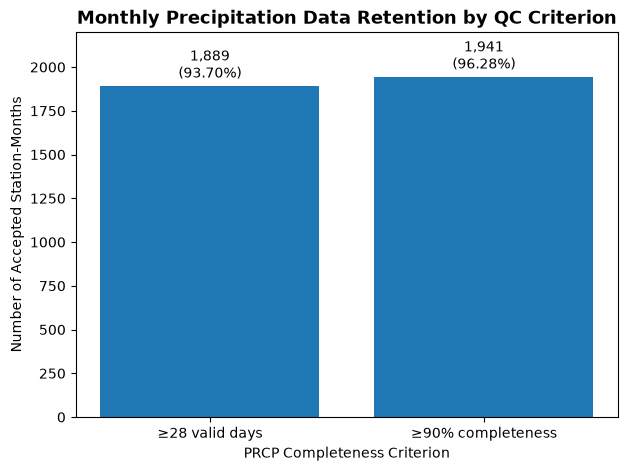

In [47]:
accepted_28 = ~invalid_28
accepted_90 = ~invalid_90

thresholds = ['≥28 valid days', '≥90% completeness']
accepted_counts = [accepted_28.sum(), accepted_90.sum()]
total_months = len(monthly_base)

labels = [
    f'{count:,}\n({count / total_months:.2%})'
    for count in accepted_counts
]

fig, ax = plt.subplots(figsize=(7,5))
bars = ax.bar(thresholds, accepted_counts)

ax.set_xlabel('PRCP Completeness Criterion')
ax.set_ylabel('Number of Accepted Station-Months')
ax.set_title("Monthly Precipitation Data Retention by QC Criterion",
             fontsize=13, fontweight='bold')

ax.bar_label(bars, labels=labels,fmt='{:,.0f}',padding=3)
ax.set_ylim(0,2200)

fig.savefig(
    FIGURES_DIR / 'qc_threshold_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [48]:
print(cleaned.columns)

Index(['STATION', 'DATE', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'NAME', 'TEMP',
       'TEMP_ATTRIBUTES', 'DEWP', 'DEWP_ATTRIBUTES', 'SLP', 'SLP_ATTRIBUTES',
       'STP', 'STP_ATTRIBUTES', 'VISIB', 'VISIB_ATTRIBUTES', 'WDSP',
       'WDSP_ATTRIBUTES', 'MXSPD', 'GUST', 'MAX', 'MAX_ATTRIBUTES', 'MIN',
       'MIN_ATTRIBUTES', 'PRCP', 'PRCP_ATTRIBUTES', 'SNDP', 'FRSHTT', 'MONTH'],
      dtype='str')


In [49]:
## Aggregating Monthly Weather Features

weather_groups = cleaned.groupby(['STATION','MONTH'])

# Calculate monthly means
monthly_weather = weather_groups.agg(
    TEMP_MEAN = ('TEMP' , 'mean'),
    DEWP_MEAN= ('DEWP', 'mean'),
    WDSP_MEAN = ('WDSP', 'mean')
).reset_index()

print("Shape:", monthly_weather.shape)
display(monthly_weather.head())

Shape: (2015, 5)


,STATION,MONTH,TEMP_MEAN,DEWP_MEAN,WDSP_MEAN
0,41184099999,1996-01,18.333333,13.448029,6.284852
1,41184099999,1996-02,19.591954,14.896552,6.980124
2,41184099999,1996-03,22.724014,16.976703,8.602839
3,41184099999,1996-04,27.048148,16.362963,7.864827
4,41184099999,1996-05,31.620072,18.120072,7.234748


In [50]:
# Merging monthly weather features

monthly_features = pd.merge(monthly_base, monthly_weather, on=['STATION', 'MONTH'], how='left')

print('Shape:', monthly_features.shape)

weather_columns = ['TEMP_MEAN', 'DEWP_MEAN', 'WDSP_MEAN']
print(monthly_features[weather_columns].isna().sum())


Shape: (2016, 9)
TEMP_MEAN    1
DEWP_MEAN    1
WDSP_MEAN    1
dtype: int64


IMPORTANT NOTE: 

having a TEMP_MEAN value doesn't mean it's accurate, because if a month is 31 days but the temp is available for only two days, mean() gets the mean for those two days.

so the next question is:
is the monthly mean is calculated from enough number of days?


In [51]:
# Checking weather feature completeness

weather_counts = weather_groups.agg(
    TEMP_VALID_DAYS = ('TEMP', 'count'),
    DEWP_VALID_DAYS= ('DEWP', 'count'),
    WDSP_VALID_DAYS= ('WDSP', 'count')
).reset_index()

monthly_features = pd.merge(monthly_features, weather_counts, on=['STATION','MONTH'], how='left')

print("Shape:", monthly_features.shape)
display(monthly_features.head())

Shape: (2016, 12)


,STATION,MONTH,PRCP_VALID_DAYS,PRCP_TOTAL,DAYS_IN_MONTH,PRCP_COMPLETENESS,TEMP_MEAN,DEWP_MEAN,WDSP_MEAN,TEMP_VALID_DAYS,DEWP_VALID_DAYS,WDSP_VALID_DAYS
0,41184099999,1996-01,29.0,0.0,31,93.548387,18.333333,13.448029,6.284852,31.0,31.0,31.0
1,41184099999,1996-02,27.0,0.0,29,93.103448,19.591954,14.896552,6.980124,29.0,29.0,29.0
2,41184099999,1996-03,28.0,0.0,31,90.322581,22.724014,16.976703,8.602839,31.0,31.0,31.0
3,41184099999,1996-04,30.0,0.0,30,100.000000,27.048148,16.362963,7.864827,30.0,30.0,30.0
4,41184099999,1996-05,31.0,0.0,31,100.000000,31.620072,18.120072,7.234748,31.0,31.0,31.0


In [52]:
# Adding each feature completeness percentage

monthly_features['TEMP_COMPLETENESS'] = monthly_features['TEMP_VALID_DAYS'] / monthly_features['DAYS_IN_MONTH'] *100
monthly_features['DEWP_COMPLETENESS'] = monthly_features['DEWP_VALID_DAYS'] / monthly_features['DAYS_IN_MONTH'] *100
monthly_features['WDSP_COMPLETENESS'] = monthly_features['WDSP_VALID_DAYS'] / monthly_features['DAYS_IN_MONTH'] *100

monthly_features[['TEMP_COMPLETENESS','DEWP_COMPLETENESS','WDSP_COMPLETENESS']].describe()

,TEMP_COMPLETENESS,DEWP_COMPLETENESS,WDSP_COMPLETENESS
count,2015.000000,2015.000000,2015.000000
mean,99.669228,99.667627,99.669228
std,2.857430,2.858148,2.857430
min,19.354839,19.354839,19.354839
25%,100.000000,100.000000,100.000000
50%,100.000000,100.000000,100.000000
75%,100.000000,100.000000,100.000000
max,100.000000,100.000000,100.000000


In [53]:
weather_cols = [
    "TEMP_COMPLETENESS",
    "DEWP_COMPLETENESS",
    "WDSP_COMPLETENESS"
]

low_completeness = monthly_features[weather_cols].lt(90).any(axis=1)
missing_completeness = monthly_features[weather_cols].isna().any(axis=1)
mask = (low_completeness | missing_completeness)

low_completeness_months = monthly_features[mask] 

print("Low completeness percentage months:", low_completeness_months.shape[0])
display(low_completeness_months)

Low completeness percentage months: 17


,STATION,MONTH,PRCP_VALID_DAYS,PRCP_TOTAL,DAYS_IN_MONTH,PRCP_COMPLETENESS,TEMP_MEAN,DEWP_MEAN,WDSP_MEAN,TEMP_VALID_DAYS,DEWP_VALID_DAYS,WDSP_VALID_DAYS,TEMP_COMPLETENESS,DEWP_COMPLETENESS,WDSP_COMPLETENESS
21,41184099999,1997-10,22.0,0.000,31,70.967742,29.083333,19.893939,7.576364,22.0,22.0,22.0,70.967742,70.967742,70.967742
119,41184099999,2005-12,6.0,0.000,31,19.354839,22.314815,17.018519,4.660867,6.0,6.0,6.0,19.354839,19.354839,19.354839
120,41184099999,2006-01,NaN,NaN,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
121,41184099999,2006-02,13.0,5.080,28,46.428571,21.285185,15.133333,7.062293,15.0,15.0,15.0,53.571429,53.571429,53.571429
301,41184099999,2021-02,25.0,0.000,28,89.285714,20.573333,12.815556,8.756256,25.0,25.0,25.0,89.285714,89.285714,89.285714
637,41194099999,2021-02,25.0,0.000,28,89.285714,22.528889,14.100000,11.519440,25.0,25.0,25.0,89.285714,89.285714,89.285714
693,41196099999,1997-10,21.0,0.000,31,67.741935,28.058201,20.253968,10.018438,21.0,21.0,21.0,67.741935,67.741935,67.741935
973,41196099999,2021-02,25.0,0.000,28,89.285714,21.293333,13.211111,9.719296,25.0,25.0,25.0,89.285714,89.285714,89.285714
1029,41198099999,1997-10,22.0,0.000,31,70.967742,29.878788,21.808081,8.510782,22.0,22.0,22.0,70.967742,70.967742,70.967742
1059,41198099999,2000-04,26.0,0.000,30,86.666667,31.519231,13.222222,12.016631,26.0,26.0,26.0,86.666667,86.666667,86.666667


In [54]:
affected_stations = low_completeness_months.groupby("MONTH")['STATION'].nunique()
affected_stations = affected_stations.sort_values(ascending=False)
display(affected_stations)

MONTH
2021-02    6
1997-10    4
2000-04    1
2004-10    1
2002-07    1
2004-11    1
2005-12    1
2006-01    1
2006-02    1
Freq: M, Name: STATION, dtype: int64

In [55]:
feb_2021 = cleaned[
    (cleaned['DATE'].dt.year == 2021) &
    (cleaned['DATE'].dt.month ==  2)
]

daily_counts = feb_2021.groupby("STATION")['DATE'].nunique()
display(daily_counts)

expected_dates = pd.date_range(
    start="2021-02-01",
    end='2021-02-28'
)

for station in feb_2021['STATION'].unique():

    station_data = feb_2021[
        feb_2021["STATION"] == station
    ]

    observed_dates = pd.DatetimeIndex(
        station_data["DATE"]
    )

    missing_dates = expected_dates.difference(observed_dates)

    print("Station:", station)
    print("Missing dates:", missing_dates)
    print("Number of missing dates:", len(missing_dates))

STATION
41184099999    25
41194099999    25
41196099999    25
41198099999    25
41217099999    25
41218099999    25
Name: DATE, dtype: int64

Station: 41184099999
Missing dates: DatetimeIndex(['2021-02-11', '2021-02-12', '2021-02-20'], dtype='datetime64[us]', freq=None)
Number of missing dates: 3
Station: 41194099999
Missing dates: DatetimeIndex(['2021-02-11', '2021-02-12', '2021-02-20'], dtype='datetime64[us]', freq=None)
Number of missing dates: 3
Station: 41196099999
Missing dates: DatetimeIndex(['2021-02-11', '2021-02-12', '2021-02-20'], dtype='datetime64[us]', freq=None)
Number of missing dates: 3
Station: 41198099999
Missing dates: DatetimeIndex(['2021-02-11', '2021-02-12', '2021-02-20'], dtype='datetime64[us]', freq=None)
Number of missing dates: 3
Station: 41217099999
Missing dates: DatetimeIndex(['2021-02-11', '2021-02-12', '2021-02-20'], dtype='datetime64[us]', freq=None)
Number of missing dates: 3
Station: 41218099999
Missing dates: DatetimeIndex(['2021-02-11', '2021-02-12', '2021-02-20'], dtype='datetime64[us]', freq=None)
Number of missing dates: 3


In [56]:
missing_dates = pd.to_datetime([
    "2021-02-11",
    "2021-02-12",
    "2021-02-20"
])

raw_missing_check = raw[
    raw['DATE'].isin(missing_dates)
]
station_counts = raw_missing_check.groupby("DATE")['STATION'].nunique()
display(station_counts)

Series([], Name: STATION, dtype: int64)

In [57]:

# Task 5.15 — Step 2
# Audit MIN and MAX temperature columns

# TODO 1: Display descriptive statistics
# for MIN and MAX in raw data.

raw_stats = raw[["MIN", "MAX"]].describe()
display(raw_stats)

# TODO 2: Count missing values in cleaned data.

missing_counts = cleaned[["MIN", "MAX"]].isna().sum()
display(missing_counts)

# TODO 3: Calculate missing percentages.
# Hint: Divide missing counts by total rows, then * 100.
total_rows = cleaned.shape[0]
missing_pct = missing_counts/total_rows * 100
display(missing_pct)

  

,MIN,MAX
count,61130.000000,61130.000000
mean,73.786282,95.115644
std,70.487464,70.542880
min,34.000000,56.500000
25%,64.200000,83.500000
50%,73.900000,95.700000
75%,83.300000,105.800000
max,9999.900000,9999.900000


MIN    3
MAX    3
dtype: int64

MIN    0.004908
MAX    0.004908
dtype: float64

In [58]:
monthly_temp = cleaned.groupby(
    [
        'STATION',
        cleaned['DATE'].dt.year.rename("YEAR"),
        cleaned['DATE'].dt.month.rename("MONTH")
    ]
).agg(
    TEMP_MIN_MEAN=('MIN','mean'),
    TEMP_MAX_MEAN=('MAX', 'mean'),
    TEMP_MIN_ABS=('MIN','min'),
    TEMP_MAX_ABS=("MAX",'max')
).reset_index()

display(monthly_temp.head())

,STATION,YEAR,MONTH,TEMP_MIN_MEAN,TEMP_MAX_MEAN,TEMP_MIN_ABS,TEMP_MAX_ABS
0,41184099999,1996,1,12.378136,23.935484,6.388889,27.777778
1,41184099999,1996,2,13.281609,25.831418,8.222222,29.722222
2,41184099999,1996,3,17.258065,28.840502,12.388889,33.111111
3,41184099999,1996,4,18.666667,35.477778,13.111111,40.777778
4,41184099999,1996,5,21.700717,40.962366,17.888889,44.722222


In [59]:
duplicate_count = monthly_temp.duplicated(
    subset=['STATION','YEAR','MONTH']
).sum()

print("Duplicate station-months:", duplicate_count)



Duplicate station-months: 0


In [60]:

monthly_temp['MONTH_PERIOD'] = pd.PeriodIndex.from_fields(
    year=monthly_temp['YEAR'],
    month=monthly_temp['MONTH'],
    freq='M'
)

print(monthly_temp['MONTH_PERIOD'].dtype)
display(monthly_temp[["STATION", "YEAR", "MONTH", "MONTH_PERIOD"]].head())

duplicate_keys = monthly_temp.duplicated(
    subset=['STATION','MONTH_PERIOD']
).sum()
print("Duplicated keys:", duplicate_keys)

period[M]


,STATION,YEAR,MONTH,MONTH_PERIOD
0,41184099999,1996,1,1996-01
1,41184099999,1996,2,1996-02
2,41184099999,1996,3,1996-03
3,41184099999,1996,4,1996-04
4,41184099999,1996,5,1996-05


Duplicated keys: 0


In [61]:
# Merging the two features tables
temp_cols = [
    'STATION',
    'MONTH_PERIOD',
    'TEMP_MIN_MEAN',
    'TEMP_MAX_MEAN',
    'TEMP_MIN_ABS',
    'TEMP_MAX_ABS'
]

left_duplicates = monthly_features.duplicated(
    subset=['STATION','MONTH']
).sum()

print("Left duplicates:", left_duplicates)

monthly_features_merged = monthly_features.merge(
    monthly_temp[temp_cols],
    how="left",
    left_on=['STATION','MONTH'],
    right_on=['STATION','MONTH_PERIOD'],
    validate='one_to_one',
    indicator=True
)
monthly_features_merged['MONTH_PERIOD']= (monthly_features_merged['MONTH'])
print("Missing MONTH_PERIOD:", monthly_features_merged['MONTH_PERIOD'].isna().sum())
display(
    monthly_features_merged.loc[
        (monthly_features_merged["STATION"] == "41184099999")
        & (
            monthly_features_merged["MONTH"]
            == pd.Period("2006-01", freq="M")
        ),
        ["STATION", "MONTH", "MONTH_PERIOD", "PRCP_TOTAL"]
    ]
)
print("-"*50)


print("Original rows:", len(monthly_features))
print("Merged rows:", len(monthly_features_merged))
print(monthly_features_merged["_merge"].value_counts())

Left duplicates: 0
Missing MONTH_PERIOD: 0


,STATION,MONTH,MONTH_PERIOD,PRCP_TOTAL
120,41184099999,2006-01,2006-01,NaN


--------------------------------------------------
Original rows: 2016
Merged rows: 2016
_merge
both          2015
left_only        1
right_only       0
Name: count, dtype: int64


In [62]:
unmatched = monthly_features_merged[
    monthly_features_merged['_merge'] == 'left_only'
]

display(unmatched[
    ['STATION', 'MONTH', 'TEMP_MIN_MEAN','TEMP_MAX_MEAN',
     'TEMP_MIN_ABS', 'TEMP_MAX_ABS']
])

new_temp_cols = [
    'TEMP_MIN_MEAN', 'TEMP_MAX_MEAN', 'TEMP_MIN_ABS', 'TEMP_MAX_ABS'
]
print(monthly_features_merged[new_temp_cols].isna().sum())

,STATION,MONTH,TEMP_MIN_MEAN,TEMP_MAX_MEAN,TEMP_MIN_ABS,TEMP_MAX_ABS
120,41184099999,2006-01,NaN,NaN,NaN,NaN


TEMP_MIN_MEAN    1
TEMP_MAX_MEAN    1
TEMP_MIN_ABS     1
TEMP_MAX_ABS     1
dtype: int64


In [63]:
monthly_temp_counts = cleaned.groupby(
    [
        'STATION',
        cleaned['DATE'].dt.to_period("M").rename("MONTH")
    ]
).agg(
    MIN_VALID_DAYS=("MIN", 'count'),
    MAX_VALID_DAYS=("MAX", 'count'),
).reset_index()

display(monthly_temp_counts.head())

,STATION,MONTH,MIN_VALID_DAYS,MAX_VALID_DAYS
0,41184099999,1996-01,31,31
1,41184099999,1996-02,29,29
2,41184099999,1996-03,31,31
3,41184099999,1996-04,30,30
4,41184099999,1996-05,31,31


In [64]:
# calculating monthly completeness

monthly_temp_counts['DAYS_IN_MONTH'] = (
    monthly_temp_counts['MONTH'].dt.days_in_month
)

monthly_temp_counts['MIN_COMPLETENESS'] = (
    monthly_temp_counts['MIN_VALID_DAYS']
    / monthly_temp_counts['DAYS_IN_MONTH']
    * 100
)

monthly_temp_counts['MAX_COMPLETENESS'] = (
    monthly_temp_counts['MAX_VALID_DAYS']
    / monthly_temp_counts['DAYS_IN_MONTH']
    * 100
)

display(
    monthly_temp_counts[
        ['MIN_COMPLETENESS', 'MAX_COMPLETENESS']
    ].describe()
)

,MIN_COMPLETENESS,MAX_COMPLETENESS
count,2015.000000,2015.000000
mean,99.664319,99.664372
std,2.861620,2.861565
min,19.354839,19.354839
25%,100.000000,100.000000
50%,100.000000,100.000000
75%,100.000000,100.000000
max,100.000000,100.000000


In [65]:
# Identifing low-completeness months

low_temp_mask = (
    (monthly_temp_counts['MIN_COMPLETENESS'] < 90)
    |
    (monthly_temp_counts['MAX_COMPLETENESS'] < 90)
)

low_temp_months = monthly_temp_counts[low_temp_mask]

print("Low completeness station-months:", len(low_temp_months))

display(
    low_temp_months[
        ['STATION', 'MONTH', 'MIN_COMPLETENESS', 'MAX_COMPLETENESS']
    ]
)

Low completeness station-months: 16


,STATION,MONTH,MIN_COMPLETENESS,MAX_COMPLETENESS
21,41184099999,1997-10,70.967742,70.967742
119,41184099999,2005-12,19.354839,19.354839
120,41184099999,2006-02,53.571429,53.571429
300,41184099999,2021-02,89.285714,89.285714
636,41194099999,2021-02,89.285714,89.285714
692,41196099999,1997-10,67.741935,67.741935
972,41196099999,2021-02,89.285714,89.285714
1028,41198099999,1997-10,70.967742,70.967742
1058,41198099999,2000-04,86.666667,86.666667
1085,41198099999,2002-07,83.870968,83.870968


In [66]:

# Compare flagged station-month keys

# Previous weather QC flags
weather_cols = [
    "TEMP_COMPLETENESS",
    "DEWP_COMPLETENESS",
    "WDSP_COMPLETENESS"
]

weather_mask = (
    monthly_features[weather_cols].lt(90).any(axis=1)
    | monthly_features[weather_cols].isna().any(axis=1)
)

weather_keys = set(
    zip(
        monthly_features.loc[weather_mask, "STATION"],
        monthly_features.loc[weather_mask, "MONTH"]
    )
)

temp_keys = set(
    zip(
        low_temp_months["STATION"],
        low_temp_months["MONTH"]
    )
)

difference = weather_keys - temp_keys

print("Weather flagged:", len(weather_keys))
print("MIN/MAX flagged:", len(temp_keys))
print("Weather-only keys:", difference)


Weather flagged: 17
MIN/MAX flagged: 16
Weather-only keys: {('41184099999', Period('2006-01', 'M'))}


In [67]:
# creating next-month target

model_df = monthly_features_merged.copy()

model_df = model_df.sort_values(
    ['STATION','MONTH']
)

model_df['TARGET_NEXT_MONTH'] = (
    model_df.groupby("STATION")['PRCP_TOTAL']
    .shift(-1)
)
display(
    model_df[
        model_df['STATION'] == '41184099999'
    ][['MONTH', 'PRCP_TOTAL', 'TARGET_NEXT_MONTH']].head(8)
)

,MONTH,PRCP_TOTAL,TARGET_NEXT_MONTH
0,1996-01,0.0,0.0
1,1996-02,0.0,0.0
2,1996-03,0.0,0.0
3,1996-04,0.0,0.0
4,1996-05,0.0,0.0
5,1996-06,0.0,0.0
6,1996-07,0.0,0.0
7,1996-08,0.0,0.0


In [68]:

# Inspect months around the missing period

rak_check = model_df[
    (model_df["STATION"] == "41184099999")
    &
    (model_df["MONTH"] >= pd.Period("2005-11", freq="M"))
    &
    (model_df["MONTH"] <= pd.Period("2006-03", freq="M"))
]

display(
    rak_check[
        [
            "MONTH",
            "PRCP_TOTAL",
            "PRCP_VALID_DAYS",
            "TARGET_NEXT_MONTH"
        ]
    ]
)


,MONTH,PRCP_TOTAL,PRCP_VALID_DAYS,TARGET_NEXT_MONTH
118,2005-11,0.00,30.0,0.00
119,2005-12,0.00,6.0,NaN
120,2006-01,NaN,NaN,5.08
121,2006-02,5.08,13.0,0.00
122,2006-03,0.00,30.0,0.00


In [69]:

# Align target rainfall completeness

model_df = model_df.sort_values(
    ["STATION", "MONTH"]
).copy()

model_df["TARGET_COMPLETENESS"] = (
    model_df.groupby("STATION")["PRCP_COMPLETENESS"]
    .shift(-1)
)

model_df["TARGET_VALID_DAYS"] = (
    model_df.groupby("STATION")["PRCP_VALID_DAYS"]
    .shift(-1)
)

display(
    model_df.loc[
        (model_df["STATION"] == "41184099999")
        & model_df["MONTH"].between(
            pd.Period("2005-11", freq="M"),
            pd.Period("2006-03", freq="M")
        ),
        [
            "MONTH",
            "PRCP_TOTAL",
            "TARGET_NEXT_MONTH",
            "TARGET_COMPLETENESS",
            "TARGET_VALID_DAYS"
        ]
    ]
)
  

,MONTH,PRCP_TOTAL,TARGET_NEXT_MONTH,TARGET_COMPLETENESS,TARGET_VALID_DAYS
118,2005-11,0.00,0.00,19.354839,6.0
119,2005-12,0.00,NaN,NaN,NaN
120,2006-01,NaN,5.08,46.428571,13.0
121,2006-02,5.08,0.00,96.774194,30.0
122,2006-03,0.00,0.00,100.000000,30.0


In [70]:

# Comparing target QC policies

# Policy A — at least 90% completeness
model_df["TARGET_QC_90"] = (
    model_df["TARGET_COMPLETENESS"] >= 90
)

# Policy B — at least 28 valid days
model_df["TARGET_QC_28"] = (
    model_df["TARGET_VALID_DAYS"] >= 28
)

print("90% QC accepted:",
      model_df["TARGET_QC_90"].sum())

print("28-day QC accepted:",
      model_df["TARGET_QC_28"].sum())

disagreement = (
    model_df["TARGET_QC_90"]
    != model_df["TARGET_QC_28"]
)

print("Disagreements:", disagreement.sum())
  

90% QC accepted: 1940
28-day QC accepted: 1888
Disagreements: 52


In [71]:

# Investigate QC disagreements

extra_targets = model_df[
    (model_df["TARGET_QC_90"] == True)
    &
    (model_df["TARGET_QC_28"] == False)
].copy()

extra_targets["TARGET_MONTH"] = (
    extra_targets["MONTH"] + 1
)

print(
    extra_targets["TARGET_MONTH"]
    .dt.month
    .value_counts()
    .sort_index()
)

print("Total:", len(extra_targets))
  

TARGET_MONTH
2    45
4     7
Name: count, dtype: int64
Total: 52


In [72]:

#  Investigate valid days

extra_targets["TARGET_DAYS_IN_MONTH"] = (
    extra_targets["TARGET_MONTH"].dt.days_in_month
)

summary = (
    extra_targets.groupby(
        ["TARGET_DAYS_IN_MONTH", "TARGET_VALID_DAYS"]
    )
    .size()
    .reset_index(name="COUNT")
)

display(summary)

print("Total:", summary["COUNT"].sum())


,TARGET_DAYS_IN_MONTH,TARGET_VALID_DAYS,COUNT
0,28,26.0,15
1,28,27.0,25
2,29,27.0,5
3,30,27.0,7


Total: 52


The 52 additional rainfall targets retained under the 90% completeness criterion were examined by calendar-month length and valid observation count. Forty-five occurred in February, including 40 observations from 28-day months and five from leap-year Februaries. The remaining seven occurred in 30-day Aprils. All 52 observations satisfied the percentage-based threshold but failed the fixed minimum of 28 valid days.


In [73]:

# Check input feature completeness

input_qc_cols = [
    "TEMP_COMPLETENESS",
    "DEWP_COMPLETENESS",
    "WDSP_COMPLETENESS"
]

model_df["INPUT_QC_90"] = (
    model_df[input_qc_cols] >= 90
).all(axis=1)

model_df["ELIGIBLE_90"] = (
    model_df["INPUT_QC_90"]
    & model_df["TARGET_QC_90"]
)

print("Input QC passed:",
      model_df["INPUT_QC_90"].sum())

print("Target QC passed:",
      model_df["TARGET_QC_90"].sum())

print("Both passed:",
      model_df["ELIGIBLE_90"].sum())


Input QC passed: 1999
Target QC passed: 1940
Both passed: 1926


In [74]:

#  Add MIN/MAX completeness

temp_qc_cols = [
    "STATION",
    "MONTH",
    "MIN_COMPLETENESS",
    "MAX_COMPLETENESS"
]

model_df = model_df.merge(
    monthly_temp_counts[temp_qc_cols],
    on=["STATION", "MONTH"],
    how="left",
    validate="one_to_one"
)

all_input_qc_cols = [
    "TEMP_COMPLETENESS",
    "DEWP_COMPLETENESS",
    "WDSP_COMPLETENESS",
    "MIN_COMPLETENESS",
    "MAX_COMPLETENESS"
]

model_df["INPUT_QC_ALL_90"] = (
    model_df[all_input_qc_cols] >= 90
).all(axis=1)

model_df["ELIGIBLE_ALL_90"] = (
    model_df["INPUT_QC_ALL_90"]
    & model_df["TARGET_QC_90"]
)

print("Previous eligible:", model_df["ELIGIBLE_90"].sum())
print("New eligible:", model_df["ELIGIBLE_ALL_90"].sum())
print("Additional excluded:",
      model_df["ELIGIBLE_90"].sum()
      - model_df["ELIGIBLE_ALL_90"].sum())

print("Total rows:", len(model_df))


Previous eligible: 1926
New eligible: 1926
Additional excluded: 0
Total rows: 2016


In [75]:
# Missing value audit

eligible_df = model_df[ model_df['ELIGIBLE_ALL_90']].copy()

features_to_check = [
    'TEMP_MEAN',
    'DEWP_MEAN',
    'WDSP_MEAN',
    'TEMP_MIN_MEAN',
    'TEMP_MAX_MEAN',
    'TEMP_MIN_ABS',
    'TEMP_MAX_ABS',
    'TARGET_NEXT_MONTH'
]

missing_counts = (
    eligible_df[features_to_check].isna().sum()
)

print("Missing values per feature:\n", missing_counts)

rows_with_missing = (
    eligible_df[features_to_check].isna().any(axis=1).sum()
)

print("Rows with missing values:", rows_with_missing)
print("Eligible rows:", len(eligible_df))

Missing values per feature:
 TEMP_MEAN            0
DEWP_MEAN            0
WDSP_MEAN            0
TEMP_MIN_MEAN        0
TEMP_MAX_MEAN        0
TEMP_MIN_ABS         0
TEMP_MAX_ABS         0
TARGET_NEXT_MONTH    0
dtype: int64
Rows with missing values: 0
Eligible rows: 1926


In [76]:
# Investigating Eligible observations by station

station_summary = (
    eligible_df.groupby("STATION").size().reset_index(name="ELIGIBLE_MONTHS")
)

station_summary['PERCENTAGE'] = (
    station_summary['ELIGIBLE_MONTHS'] / len(eligible_df) * 100
)

display(station_summary)

print("Total eligible:", station_summary['ELIGIBLE_MONTHS'].sum())
print("Number of stations:", station_summary['STATION'].nunique())


,STATION,ELIGIBLE_MONTHS,PERCENTAGE
0,41184099999,320,16.614746
1,41194099999,328,17.030114
2,41196099999,321,16.666667
3,41198099999,311,16.147456
4,41217099999,326,16.926272
5,41218099999,320,16.614746


Total eligible: 1926
Number of stations: 6


Average eligible months per station is 321 and the highest station eligible months is station 41194099999 with 328 months. The lowest is station 41198099999 with 311 months. The difference is 17 months.  

Every station contributes around 16-17% of observations, so no single station takes control over dataset size.


In [77]:
# Auditing temporal coverage

eligible_df['YEAR'] = (
    eligible_df['MONTH'].dt.year
)

yearly_coverage = (
    eligible_df.groupby("YEAR").size().reset_index(name="ELIGIBLE_MONTHS")
)
total_years = 6 * 12 # 6 stations * 12 months
yearly_coverage['MISSING_MONTHS'] = (
    total_years - yearly_coverage ['ELIGIBLE_MONTHS'] 
)

display(yearly_coverage.sort_values('MISSING_MONTHS', ascending=False).head(10))

print("Total missing station-months:", yearly_coverage['MISSING_MONTHS'].sum())

,YEAR,ELIGIBLE_MONTHS,MISSING_MONTHS
25,2021,55,17
3,1999,63,9
1,1997,64,8
6,2002,65,7
7,2003,66,6
27,2023,66,6
21,2017,66,6
0,1996,66,6
20,2016,69,3
4,2000,69,3


Total missing station-months: 90


Following the application of the 90% input and target completeness criteria, 1,926 of 2,016 station-month observations remained eligible. Temporal coverage analysis identified 2021 as the year with the highest exclusion count, with 17 of 72 station-month observations excluded. 

In [78]:
# Investigate exclusions in 2021

data_2021 = model_df[model_df['MONTH'].dt.year == 2021].copy()
excluded_2021 = data_2021[data_2021["ELIGIBLE_ALL_90"] == False].copy()

station_exclusions = (excluded_2021.groupby("STATION").size().reset_index(name="EXCLUDED_MONTHS"))
display(station_exclusions)

monthly_exclusions = (excluded_2021.groupby(excluded_2021['MONTH'].dt.month).size())
print("Exclusions by month:\n", monthly_exclusions)
print("Total excluded:", len(excluded_2021))


,STATION,EXCLUDED_MONTHS
0,41184099999,3
1,41194099999,3
2,41196099999,3
3,41198099999,2
4,41217099999,3
5,41218099999,3


Exclusions by month:
 MONTH
1     6
2     6
12    5
dtype: int64
Total excluded: 17


In [79]:
excluded_2021 = model_df[
    (model_df['MONTH'].dt.year == 2021)
    & (~model_df['ELIGIBLE_ALL_90'])
].copy()

excluded_2021['INPUT_FAILED'] = (~excluded_2021['INPUT_QC_ALL_90'])
excluded_2021['TARGET_FAILED'] = (~excluded_2021['TARGET_QC_90'])

failure_summary = (
    excluded_2021.groupby(['INPUT_FAILED', 'TARGET_FAILED']).size().reset_index(name="COUNT")
)
display(failure_summary)
print("Total excluded:", failure_summary['COUNT'].sum())

,INPUT_FAILED,TARGET_FAILED,COUNT
0,False,True,11
1,True,False,6


Total excluded: 17


In 2021, 17 of 72 station-month observations were excluded following quality control. Eleven observations (64.7%) failed the next-month rainfall target completeness criterion, while six (35.3%) failed the meteorological input completeness criterion. No observations failed both criteria simultaneously.

In [80]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

model_df.to_csv(
    output_dir / 'monthly_qc_dataset.csv',
    index= False
)

print("Dataset exported")
print("Shape:", model_df.shape)

Dataset exported
Shape: (2016, 32)
